## Monte Carlo Prediction and On-Policy Monte Carlo Control for Black Jack

This notebook will demonstrate the implementation of two fundamental Monte Carlo (MC) methods in reinforcement learning:

1.  **MC Prediction**: To estimate the state-value function (V) or action-value function (Q) for a given policy.
2.  **On-Policy MC Control (First-Visit)**: To learn an optimal policy by iteratively improving it based on estimated action-value functions.

In [7]:
# Import necessary libraries
import numpy as np
import gymnasium as gym
from collections import defaultdict
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from functools import partial
import seaborn as sns

### 1. Black Jack Environment Setup

We'll use the `Blackjack-v1` environment from the `gymnasium` library. This is a standard environment in reinforcement learning where the goal is to get a hand value closer to 21 than the dealer, without exceeding 21.

In [2]:
# Create the Black Jack environment
env = gym.make('Blackjack-v1', sab=True) # sab=True for states to match Sutton & Barto

# Helper function to convert states to a more readable format for printing
def state_to_string(state):
    player_sum, dealer_card, usable_ace = state
    ace_str = " (usable ace)" if usable_ace else ""
    return f"Player Sum: {player_sum}, Dealer Card: {dealer_card}{ace_str}"

print("Observation Space:", env.observation_space)
print("Action Space:", env.action_space)

# Example of an initial state
initial_state, info = env.reset()
print(f"Initial State: {state_to_string(initial_state)}")

Observation Space: Tuple(Discrete(32), Discrete(11), Discrete(2))
Action Space: Discrete(2)
Initial State: Player Sum: 11, Dealer Card: 10


### 2. Monte Carlo Prediction (First-Visit)

MC Prediction aims to estimate the value function for a given policy. In First-Visit MC, the value of a state is estimated as the average of the returns seen following the first time that state is visited in an episode.

Here, we'll implement MC Prediction for the action-value function `q(s,a)` rather than `v(s)` directly, as it's more useful for control. We will use a fixed policy where the player 'sticks' if their sum is 20 or 21, and 'hits' otherwise.

In [3]:
def mc_prediction_q(env, num_episodes, policy, gamma=1.0):
    """
    Estimates the action-value function (Q) using first-visit Monte Carlo prediction.

    Args:
        env: The Gym environment.
        num_episodes: Number of episodes to run.
        policy: A function that takes a state and returns an action.
        gamma: Discount factor (default: 1.0 for episodic tasks).

    Returns:
        Q: A dictionary mapping (state, action) pairs to their estimated Q-value.
        N: A dictionary mapping (state, action) pairs to the number of times they were visited.
    """
    # Initialize dictionaries for Q-values and counts
    Q = defaultdict(lambda: np.zeros(env.action_space.n))
    N = defaultdict(lambda: np.zeros(env.action_space.n))

    for i_episode in range(1, num_episodes + 1):
        if i_episode % 10000 == 0:
            print(f"\rEpisode {i_episode}/{num_episodes}", end="")

        episode = []
        state, info = env.reset()
        done = False

        while not done:
            action = policy(state) # Get action from the given policy
            next_state, reward, done, truncated, info = env.step(action)
            episode.append((state, action, reward))
            state = next_state

        # Process the episode to calculate returns
        G = 0 # Initialize return
        # Iterate backwards through the episode to calculate returns
        # We iterate through a copy of the list because we need to modify it
        for t in range(len(episode) - 1, -1, -1):
            state_t, action_t, reward_t = episode[t]
            G = gamma * G + reward_t # Calculate discounted return

            # Check for first-visit: if (state_t, action_t) hasn't been visited before in this episode
            # at an earlier timestep
            first_visit = True
            for prev_t in range(t):
                if episode[prev_t][0] == state_t and episode[prev_t][1] == action_t:
                    first_visit = False
                    break

            if first_visit:
                N[state_t][action_t] += 1
                Q[state_t][action_t] += (G - Q[state_t][action_t]) / N[state_t][action_t] # Incremental update

    return Q, N

# Example policy: Stick on 20 or 21, hit otherwise
def stick_20_21_policy(state):
    player_sum, dealer_card, usable_ace = state
    return 0 if player_sum >= 20 else 1 # 0: Stick, 1: Hit

print("\nRunning MC Prediction with a fixed policy...")
Q_mc_pred, N_mc_pred = mc_prediction_q(env, num_episodes=500000, policy=stick_20_21_policy)
print("\nMC Prediction finished.")

# Display some estimated Q-values for illustration
print("\nEstimated Q-values for some states:")
for state in sorted(Q_mc_pred.keys()):
    if state[0] >= 17 and state[0] <= 21:
        print(f"State: {state_to_string(state)}, Q-values: {Q_mc_pred[state]}")


Running MC Prediction with a fixed policy...
Episode 500000/500000
MC Prediction finished.

Estimated Q-values for some states:
State: Player Sum: 17, Dealer Card: 1, Q-values: [ 0.         -0.75570776]
State: Player Sum: 17, Dealer Card: 1 (usable ace), Q-values: [ 0.         -0.52380952]
State: Player Sum: 17, Dealer Card: 2, Q-values: [ 0.         -0.67437488]
State: Player Sum: 17, Dealer Card: 2 (usable ace), Q-values: [ 0.        -0.4036061]
State: Player Sum: 17, Dealer Card: 3, Q-values: [ 0.         -0.68033095]
State: Player Sum: 17, Dealer Card: 3 (usable ace), Q-values: [ 0.         -0.29750779]
State: Player Sum: 17, Dealer Card: 4, Q-values: [ 0.         -0.68647184]
State: Player Sum: 17, Dealer Card: 4 (usable ace), Q-values: [ 0.         -0.30312036]
State: Player Sum: 17, Dealer Card: 5, Q-values: [ 0.        -0.6823262]
State: Player Sum: 17, Dealer Card: 5 (usable ace), Q-values: [ 0.         -0.41452991]
State: Player Sum: 17, Dealer Card: 6, Q-values: [ 0.       

### 3. On-Policy First-Visit Monte Carlo Control

MC Control aims to find an optimal policy. On-policy methods evaluate or improve the policy that is currently being followed. Here, we use a technique called **Generalized Policy Iteration (GPI)**, where policy evaluation (estimating Q) and policy improvement (making the policy greedy with respect to Q) are interleaved.

To ensure exploration, we use an **epsilon-greedy policy**, which means with probability epsilon we choose a random action, and with probability (1-epsilon) we choose the action that has the highest estimated Q-value.

In [4]:
def mc_control_epsilon_greedy(env, num_episodes, gamma=1.0, epsilon=0.1):
    """
    On-Policy First-Visit Monte Carlo Control with epsilon-greedy policy.

    Args:
        env: The Gym environment.
        num_episodes: Number of episodes to run.
        gamma: Discount factor (default: 1.0).
        epsilon: Epsilon for epsilon-greedy policy (default: 0.1).

    Returns:
        Q: Optimal action-value function.
        policy: Optimal policy (a function that takes a state and returns an action).
    """
    Q = defaultdict(lambda: np.zeros(env.action_space.n))
    N = defaultdict(lambda: np.zeros(env.action_space.n))

    # Initialize an arbitrary policy (e.g., stick on 20 or 21, hit otherwise)
    # This policy will be improved over time
    policy = defaultdict(lambda: 0) # Default to 'stick'

    for i_episode in range(1, num_episodes + 1):
        if i_episode % 10000 == 0:
            print(f"\rEpisode {i_episode}/{num_episodes}", end="")

        episode = []
        state, info = env.reset()
        done = False

        # Generate an episode using the current epsilon-greedy policy
        while not done:
            # Epsilon-greedy action selection
            if np.random.rand() < epsilon:
                action = env.action_space.sample() # Explore: choose random action
            else:
                # Exploit: choose best action according to Q
                action = np.argmax(Q[state])

            # Store the current action in the policy for this state
            policy[state] = action

            next_state, reward, done, truncated, info = env.step(action)
            episode.append((state, action, reward))
            state = next_state

        # Update Q-values and counts using returns from the episode
        G = 0
        for t in range(len(episode) - 1, -1, -1):
            state_t, action_t, reward_t = episode[t]
            G = gamma * G + reward_t

            first_visit = True
            for prev_t in range(t):
                if episode[prev_t][0] == state_t and episode[prev_t][1] == action_t:
                    first_visit = False
                    break

            if first_visit:
                N[state_t][action_t] += 1
                Q[state_t][action_t] += (G - Q[state_t][action_t]) / N[state_t][action_t]

    # After all episodes, derive the final optimal policy from the learned Q-values
    final_policy = {}
    for state in Q.keys():
        final_policy[state] = np.argmax(Q[state])

    return Q, final_policy

print("\nRunning MC Control with epsilon-greedy policy...")
Q_mc_control, optimal_policy = mc_control_epsilon_greedy(env, num_episodes=1000000, epsilon=0.1)
print("\nMC Control finished.")


Running MC Control with epsilon-greedy policy...
Episode 1000000/1000000
MC Control finished.


### 4. Evaluating the Optimal Policy

Let's visualize the learned optimal policy and its value function. We'll plot the value function `V(s) = max_a Q(s,a)` for states with and without a usable ace.


Plotting Optimal State-Value Function...


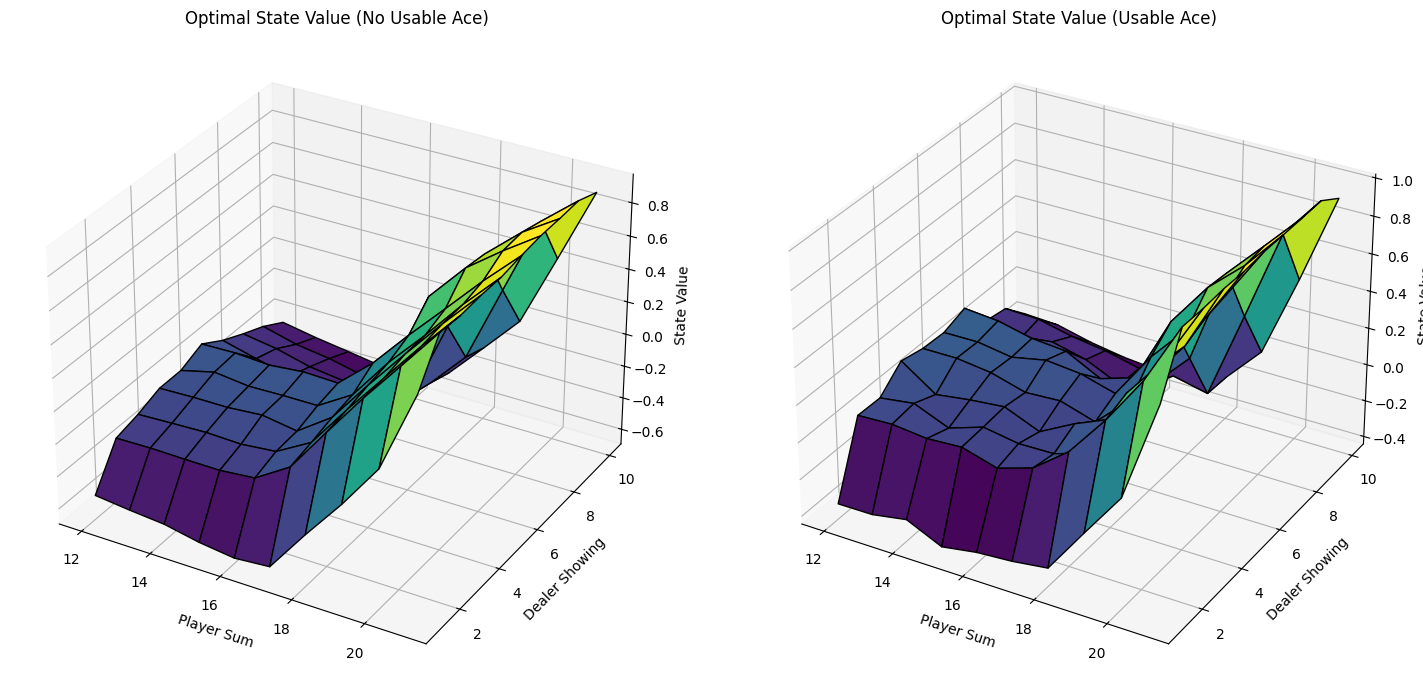

In [5]:
def plot_blackjack_values(V):
    """
    Plots the state-value function for Blackjack.

    Args:
        V: A dictionary mapping states to their estimated value (V-value).
    """
    player_sums = np.arange(12, 22)
    dealer_cards = np.arange(1, 11)

    # Grid for plotting
    X, Y = np.meshgrid(player_sums, dealer_cards)

    # Values for no usable ace
    Z_no_ace = np.zeros(X.shape)
    for i in range(len(player_sums)):
        for j in range(len(dealer_cards)):
            state = (player_sums[i], dealer_cards[j], False)
            if state in V:
                Z_no_ace[j, i] = V[state]

    # Values for usable ace
    Z_usable_ace = np.zeros(X.shape)
    for i in range(len(player_sums)):
        for j in range(len(dealer_cards)):
            state = (player_sums[i], dealer_cards[j], True)
            if state in V:
                Z_usable_ace[j, i] = V[state]

    fig = plt.figure(figsize=(15, 7))

    # Plot for no usable ace
    ax1 = fig.add_subplot(121, projection='3d')
    ax1.plot_surface(X, Y, Z_no_ace, rstride=1, cstride=1, cmap=plt.cm.viridis, edgecolor='black')
    ax1.set_xlabel('Player Sum')
    ax1.set_ylabel('Dealer Showing')
    ax1.set_zlabel('State Value')
    ax1.set_title('Optimal State Value (No Usable Ace)')

    # Plot for usable ace
    ax2 = fig.add_subplot(122, projection='3d')
    ax2.plot_surface(X, Y, Z_usable_ace, rstride=1, cstride=1, cmap=plt.cm.viridis, edgecolor='black')
    ax2.set_xlabel('Player Sum')
    ax2.set_ylabel('Dealer Showing')
    ax2.set_zlabel('State Value')
    ax2.set_title('Optimal State Value (Usable Ace)')

    plt.tight_layout()
    plt.show()

# Calculate V from Q
V_optimal = defaultdict(float)
for state, actions_q in Q_mc_control.items():
    V_optimal[state] = np.max(actions_q)

print("\nPlotting Optimal State-Value Function...")
plot_blackjack_values(V_optimal)


Plotting Optimal Policy...


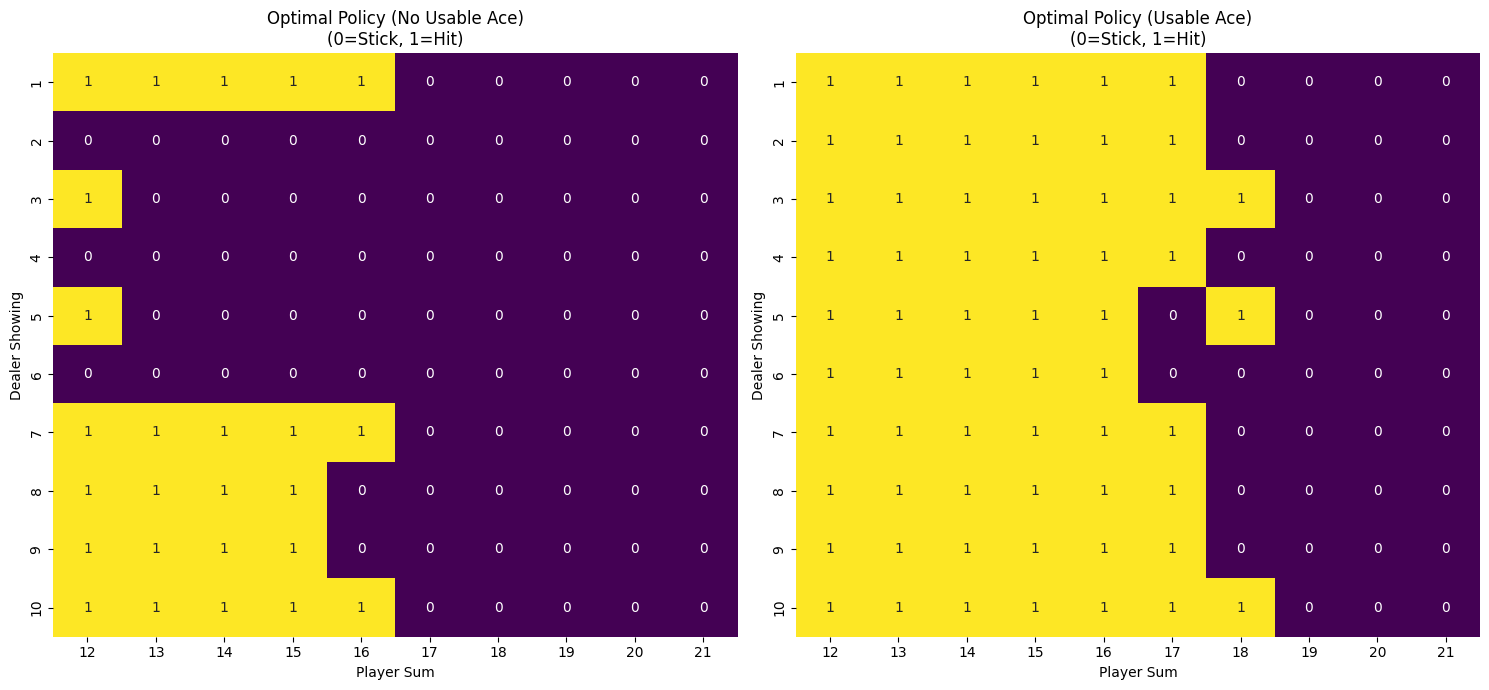

In [8]:
def plot_blackjack_policy(policy):
    """
    Plots the optimal policy for Blackjack.

    Args:
        policy: A dictionary mapping states to their optimal action.
    """
    player_sums = np.arange(12, 22)
    dealer_cards = np.arange(1, 11)

    # Policy for no usable ace
    policy_no_ace = np.zeros(len(player_sums) * len(dealer_cards)).reshape(len(dealer_cards), len(player_sums))
    for i, player_sum in enumerate(player_sums):
        for j, dealer_card in enumerate(dealer_cards):
            state = (player_sum, dealer_card, False)
            action = policy.get(state, 0) # Default to 'stick' if state not seen
            policy_no_ace[j, i] = action

    # Policy for usable ace
    policy_usable_ace = np.zeros(len(player_sums) * len(dealer_cards)).reshape(len(dealer_cards), len(player_sums))
    for i, player_sum in enumerate(player_sums):
        for j, dealer_card in enumerate(dealer_cards):
            state = (player_sum, dealer_card, True)
            action = policy.get(state, 0) # Default to 'stick' if state not seen
            policy_usable_ace[j, i] = action

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 7))

    # Plot for no usable ace
    sns.heatmap(policy_no_ace, annot=True, cmap='viridis', fmt='g', ax=ax1,
                xticklabels=player_sums, yticklabels=dealer_cards, cbar=False)
    ax1.set_xlabel('Player Sum')
    ax1.set_ylabel('Dealer Showing')
    ax1.set_title('Optimal Policy (No Usable Ace)\n(0=Stick, 1=Hit)')

    # Plot for usable ace
    sns.heatmap(policy_usable_ace, annot=True, cmap='viridis', fmt='g', ax=ax2,
                xticklabels=player_sums, yticklabels=dealer_cards, cbar=False)
    ax2.set_xlabel('Player Sum')
    ax2.set_ylabel('Dealer Showing')
    ax2.set_title('Optimal Policy (Usable Ace)\n(0=Stick, 1=Hit)')

    plt.tight_layout()
    plt.show()

print("\nPlotting Optimal Policy...")
plot_blackjack_policy(optimal_policy)